In [1]:
import sys
sys.path.append("..")  # make the src package importable from the notebooks/ folder

import matplotlib.pyplot as plt
from scipy import stats

from src.db import read_sql_file

In [2]:
counts = read_sql_file("07_arm_counts.sql")
print(counts)

# Chi-square goodness-of-fit test against the designed 1/3 : 1/3 : 1/3 split
chi2, p_value = stats.chisquare(counts["n"])
print(f"\nchi2 = {chi2:.3f}, p-value = {p_value:.4f}")

       arm      n
0  control  21306
1     mens  21307
2   womens  21387

chi2 = 0.203, p-value = 0.9037


In [3]:
balance = read_sql_file("08_covariate_balance.sql")
# MySQL DECIMAL values arrive as Python Decimal objects; convert them for numeric work
balance = balance.astype({"control_mean": float, "treatment_mean": float, "smd": float})
balance

,covariate,treatment_arm,control_mean,treatment_mean,smd
0,area_rural,mens,0.1473,0.1522,0.0137
1,area_rural,womens,0.1473,0.1487,0.0040
2,area_suburban,mens,0.4518,0.4459,-0.0117
3,area_suburban,womens,0.4518,0.4512,-0.0011
4,area_urban,mens,0.4009,0.4019,0.0020
5,area_urban,womens,0.4009,0.4001,-0.0018
6,bought_mens,mens,0.5532,0.5509,-0.0046
7,bought_mens,womens,0.5532,0.5489,-0.0086
8,bought_womens,mens,0.5476,0.5514,0.0076
9,bought_womens,womens,0.5476,0.5501,0.0049


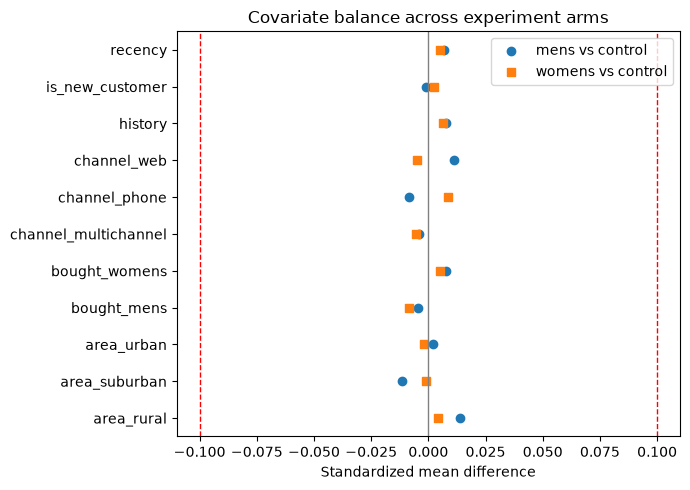

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))

for arm, marker in [("mens", "o"), ("womens", "s")]:
    subset = balance[balance["treatment_arm"] == arm]
    ax.scatter(subset["smd"], subset["covariate"], marker=marker, label=f"{arm} vs control")

ax.axvline(0, color="grey", linewidth=1)
for threshold in (-0.1, 0.1):
    ax.axvline(threshold, color="red", linestyle="--", linewidth=1)

ax.set_xlabel("Standardized mean difference")
ax.set_title("Covariate balance across experiment arms")
ax.legend()
plt.tight_layout()
fig.savefig("../reports/figures/covariate_balance.png", dpi=150)
plt.show()

## Summary of randomization checks

- **Sample ratio mismatch (SRM):** arm sizes (21,306 / 21,307 / 21,387) are consistent with the
  designed 1:1:1 split (χ² = 0.20, p = 0.90). There is no evidence of a problem with assignment or data logging.
- **Covariate balance:** across 11 pre-experiment covariates, the largest absolute standardized
  mean difference is 0.014, well below the common 0.1 threshold.
- **Conclusion:** randomization appears to have worked, so differences in outcomes between arms can be
  attributed to the emails. Balance can only be checked on observed covariates; randomization is what
  protects against imbalance in unobserved ones.